In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

df = pd.read_csv(DATA_PATH)

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df["PJME_MW"] = pd.to_numeric(df["PJME_MW"], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "PJME_MW"])
      .sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .reset_index(drop=True)
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Start:", df["Datetime"].min())
print("End:", df["Datetime"].max())
print("Missing values:\n", df[["Datetime", "PJME_MW"]].isna().sum())

Dataset loaded successfully!
Shape: (145362, 2)
Start: 2002-01-01 01:00:00
End: 2018-08-03 00:00:00
Missing values:
 Datetime    0
PJME_MW     0
dtype: int64


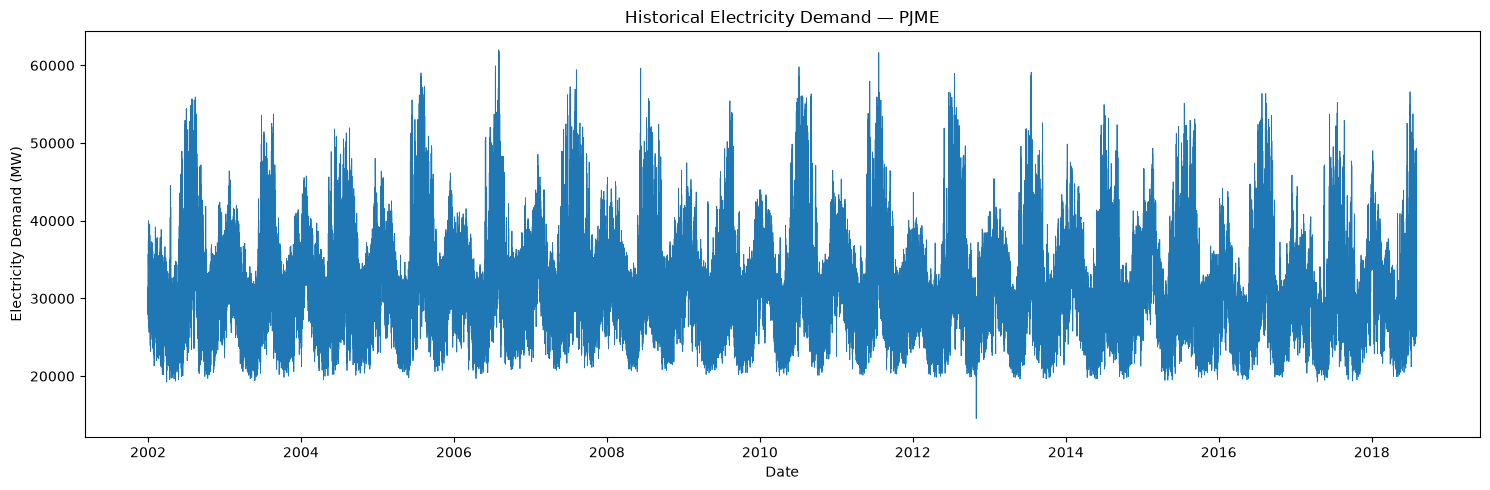

In [2]:
plt.figure(figsize=(15, 5))

plt.plot(
    df["Datetime"],
    df["PJME_MW"],
    linewidth=0.6
)

plt.title("Historical Electricity Demand — PJME")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.tight_layout()
plt.show()

In [3]:
time_diff = df["Datetime"].diff()

print("Time gap distribution:")
print(time_diff.value_counts().head(10))

print(
    "Gaps larger than one hour:",
    int((time_diff > pd.Timedelta(hours=1)).sum())
)

print(
    "Duplicate timestamps:",
    int(df["Datetime"].duplicated().sum())
)

Time gap distribution:
Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
Name: count, dtype: int64
Gaps larger than one hour: 30
Duplicate timestamps: 0


In [4]:
split_idx = int(len(df) * 0.8)

train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Training period:", train["Datetime"].min(), "to", train["Datetime"].max())
print("Testing period:", test["Datetime"].min(), "to", test["Datetime"].max())

Training rows: 116289
Testing rows: 29073
Training period: 2002-01-01 01:00:00 to 2015-04-09 12:00:00
Testing period: 2015-04-09 13:00:00 to 2018-08-03 00:00:00


In [5]:
test["Baseline_Prediction"] = (
    test["PJME_MW"].shift(1)
)

# First test prediction uses the last training observation
test.loc[test.index[0], "Baseline_Prediction"] = (
    train["PJME_MW"].iloc[-1]
)

print(
    test[
        ["Datetime", "PJME_MW", "Baseline_Prediction"]
    ].head(10)
)

                  Datetime  PJME_MW  Baseline_Prediction
116289 2015-04-09 13:00:00  32809.0              33148.0
116290 2015-04-09 14:00:00  32613.0              32809.0
116291 2015-04-09 15:00:00  32204.0              32613.0
116292 2015-04-09 16:00:00  32049.0              32204.0
116293 2015-04-09 17:00:00  32209.0              32049.0
116294 2015-04-09 18:00:00  32707.0              32209.0
116295 2015-04-09 19:00:00  33012.0              32707.0
116296 2015-04-09 20:00:00  33843.0              33012.0
116297 2015-04-09 21:00:00  33755.0              33843.0
116298 2015-04-09 22:00:00  32363.0              33755.0


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

valid = test.dropna(
    subset=["PJME_MW", "Baseline_Prediction"]
)

baseline_mae = mean_absolute_error(
    valid["PJME_MW"],
    valid["Baseline_Prediction"]
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        valid["PJME_MW"],
        valid["Baseline_Prediction"]
    )
)

print(f"Baseline MAE:  {baseline_mae:.2f} MW")
print(f"Baseline RMSE: {baseline_rmse:.2f} MW")

Baseline MAE:  1069.75 MW
Baseline RMSE: 1373.62 MW


In [7]:
def create_features(data):
    result = data.copy()
    dt = result["Datetime"]

    result["Hour"] = dt.dt.hour
    result["DayOfWeek"] = dt.dt.dayofweek
    result["Month"] = dt.dt.month
    result["DayOfYear"] = dt.dt.dayofyear
    result["IsWeekend"] = (dt.dt.dayofweek >= 5).astype(int)

    # Cyclical features: time repeats after each cycle
    result["Hour_sin"] = np.sin(2 * np.pi * result["Hour"] / 24)
    result["Hour_cos"] = np.cos(2 * np.pi * result["Hour"] / 24)

    result["Day_sin"] = np.sin(
        2 * np.pi * result["DayOfWeek"] / 7
    )
    result["Day_cos"] = np.cos(
        2 * np.pi * result["DayOfWeek"] / 7
    )

    result["Year_sin"] = np.sin(
        2 * np.pi * result["DayOfYear"] / 365.25
    )
    result["Year_cos"] = np.cos(
        2 * np.pi * result["DayOfYear"] / 365.25
    )

    return result


featured_df = create_features(df)

print("Feature engineering complete!")
print(featured_df.head())
print("Shape:", featured_df.shape)

Feature engineering complete!
             Datetime  PJME_MW  Hour  DayOfWeek  Month  DayOfYear  IsWeekend  \
0 2002-01-01 01:00:00  30393.0     1          1      1          1          0   
1 2002-01-01 02:00:00  29265.0     2          1      1          1          0   
2 2002-01-01 03:00:00  28357.0     3          1      1          1          0   
3 2002-01-01 04:00:00  27899.0     4          1      1          1          0   
4 2002-01-01 05:00:00  28057.0     5          1      1          1          0   

   Hour_sin  Hour_cos   Day_sin  Day_cos  Year_sin  Year_cos  
0  0.258819  0.965926  0.781831  0.62349  0.017202  0.999852  
1  0.500000  0.866025  0.781831  0.62349  0.017202  0.999852  
2  0.707107  0.707107  0.781831  0.62349  0.017202  0.999852  
3  0.866025  0.500000  0.781831  0.62349  0.017202  0.999852  
4  0.965926  0.258819  0.781831  0.62349  0.017202  0.999852  
Shape: (145362, 13)


In [8]:
FEATURES = [
    "Hour",
    "DayOfWeek",
    "Month",
    "DayOfYear",
    "IsWeekend",
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos",
    "Year_sin",
    "Year_cos",
]

split_idx = int(len(featured_df) * 0.8)

train = featured_df.iloc[:split_idx].copy()
test = featured_df.iloc[split_idx:].copy()

X_train = train[FEATURES]
y_train = train["PJME_MW"]

X_test = test[FEATURES]
y_test = test["PJME_MW"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Train period:", train["Datetime"].min(), "to", train["Datetime"].max())
print("Test period:", test["Datetime"].min(), "to", test["Datetime"].max())

X_train: (116289, 11)
X_test: (29073, 11)
Train period: 2002-01-01 01:00:00 to 2015-04-09 12:00:00
Test period: 2015-04-09 13:00:00 to 2018-08-03 00:00:00


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

model_mae = mean_absolute_error(y_test, predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Random Forest MAE:  {model_mae:.2f} MW")
print(f"Random Forest RMSE: {model_rmse:.2f} MW")

Random Forest MAE:  3095.94 MW
Random Forest RMSE: 3976.89 MW


In [10]:
comparison = pd.DataFrame({
    "Model": ["Persistence Baseline", "Random Forest"],
    "MAE_MW": [baseline_mae, model_mae],
    "RMSE_MW": [baseline_rmse, model_rmse],
})

display(comparison)

mae_improvement = (
    (baseline_mae - model_mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - model_rmse) / baseline_rmse
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

,Model,MAE_MW,RMSE_MW
0,Persistence Baseline,1069.75104,1373.620360
1,Random Forest,3095.94152,3976.892676


MAE improvement: -189.41%
RMSE improvement: -189.52%


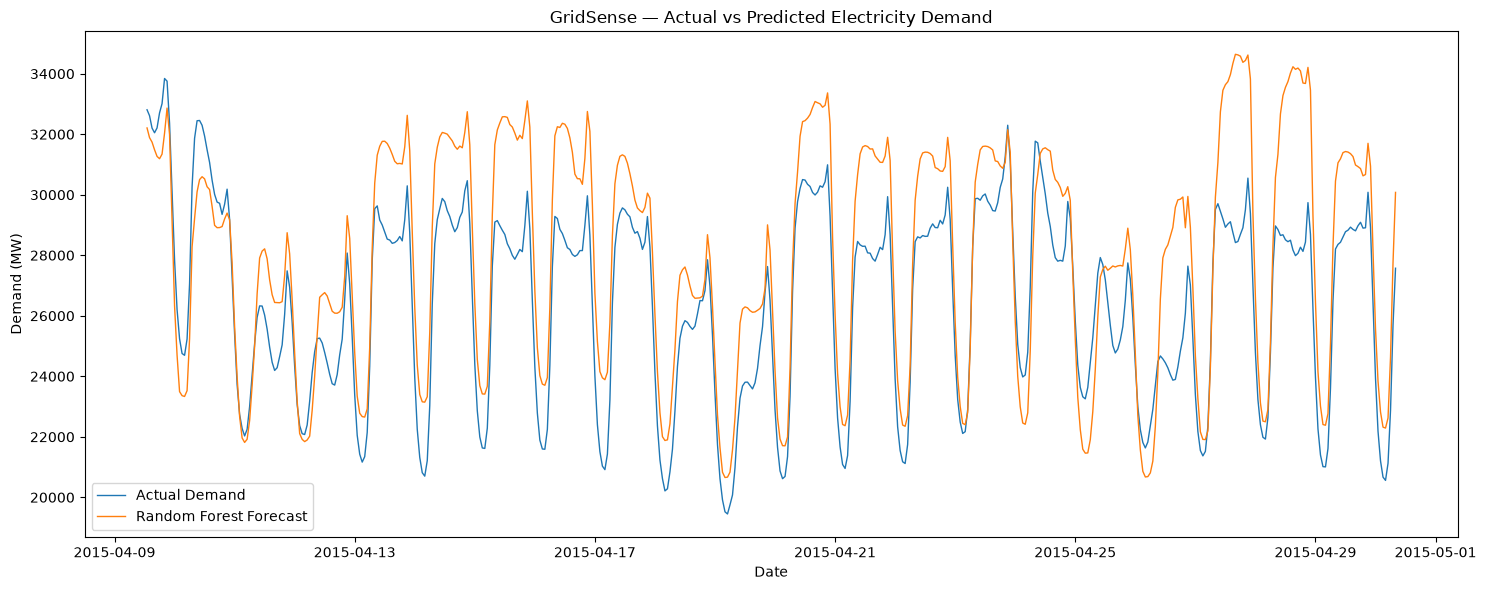

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    test["Datetime"].iloc[:500],
    y_test.iloc[:500],
    label="Actual Demand",
    linewidth=1
)

plt.plot(
    test["Datetime"].iloc[:500],
    predictions[:500],
    label="Random Forest Forecast",
    linewidth=1
)

plt.title("GridSense — Actual vs Predicted Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
print("model exists:", "model" in globals())
print("test exists:", "test" in globals())
print("predictions exists:", "predictions" in globals())
print("baseline_mae exists:", "baseline_mae" in globals())

model exists: True
test exists: True
predictions exists: True
baseline_mae exists: True


In [13]:
from pathlib import Path
import pandas as pd
import joblib

# Create processed folder
OUTPUT_PATH = Path("../data/processed")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# Save trained model
joblib.dump(
    model,
    OUTPUT_PATH / "random_forest_forecaster.joblib"
)

# Save test results
test_results = test[["Datetime", "PJME_MW"]].copy()
test_results["Forecast"] = predictions

# Persistence baseline: previous hour's actual demand
test_results["Baseline_Prediction"] = (
    test_results["PJME_MW"].shift(1)
)

test_results.loc[
    test_results.index[0],
    "Baseline_Prediction"
] = train["PJME_MW"].iloc[-1]

# Export CSV
test_results.to_csv(
    OUTPUT_PATH / "forecast_test_results.csv",
    index=False
)

print("Model and forecast results saved successfully!")
print("Saved location:", OUTPUT_PATH.resolve())
print("Results shape:", test_results.shape)

Model and forecast results saved successfully!
Saved location: C:\Users\ASUS\GridSense\data\processed
Results shape: (29073, 4)


In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load and clean data
df = pd.read_csv("../data/raw/PJME_hourly.csv")
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df["PJME_MW"] = pd.to_numeric(df["PJME_MW"], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "PJME_MW"])
      .sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .reset_index(drop=True)
)

# 2. Calendar features
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek
df["Month"] = df["Datetime"].dt.month
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

# 3. Historical demand features
df["Lag_1"] = df["PJME_MW"].shift(1)
df["Lag_24"] = df["PJME_MW"].shift(24)
df["Lag_168"] = df["PJME_MW"].shift(168)

# Rolling mean uses past observations only
df["Rolling_Mean_24"] = (
    df["PJME_MW"].shift(1).rolling(24).mean()
)

df["Rolling_Mean_168"] = (
    df["PJME_MW"].shift(1).rolling(168).mean()
)

FEATURES = [
    "Hour", "DayOfWeek", "Month", "IsWeekend",
    "Lag_1", "Lag_24", "Lag_168",
    "Rolling_Mean_24", "Rolling_Mean_168"
]

df = df.dropna(subset=FEATURES).reset_index(drop=True)

# 4. Chronological split
split_idx = int(len(df) * 0.8)
train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()

X_train = train[FEATURES]
y_train = train["PJME_MW"]
X_test = test[FEATURES]
y_test = test["PJME_MW"]

# 5. Train improved model
model_v2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model_v2.fit(X_train, y_train)
predictions_v2 = model_v2.predict(X_test)

# 6. Evaluate
mae_v2 = mean_absolute_error(y_test, predictions_v2)
rmse_v2 = np.sqrt(mean_squared_error(y_test, predictions_v2))

print(f"Random Forest V2 MAE:  {mae_v2:.2f} MW")
print(f"Random Forest V2 RMSE: {rmse_v2:.2f} MW")

# 7. Save model and results
output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model_v2,
    output_path / "random_forest_forecaster_v2.joblib"
)

results_v2 = test[["Datetime", "PJME_MW"]].copy()
results_v2["Forecast"] = predictions_v2

# Persistence baseline for the same test observations
results_v2["Baseline_Prediction"] = results_v2["PJME_MW"].shift(1)
results_v2.iloc[0, results_v2.columns.get_loc("Baseline_Prediction")] = (
    train["PJME_MW"].iloc[-1]
)

results_v2.to_csv(
    output_path / "forecast_test_results_v2.csv",
    index=False
)

print("V2 model and results saved successfully!")
print("Rows saved:", len(results_v2))

Random Forest V2 MAE:  331.36 MW
Random Forest V2 RMSE: 458.25 MW
V2 model and results saved successfully!
Rows saved: 29039
